# Writer-Adaptive Cohort-Margin Calibration for One-Class Signature Verification
### Experiment v6 — binarised protocol, trivial-baseline control, development partition

This experiment evaluates writer-adaptive calibration of a one-class support vector
machine operating in a pairwise dissimilarity representation, under a protocol that
reports a trivial-baseline control alongside every result.

### Changes from v5

**The intensity-normalised condition is withdrawn.** Rescaling each image to a fixed
mean ink intensity did not remove the acquisition cue identified in the preceding
audit: the strongest image statistic measured AUC 1.0000 after normalisation
against 0.9993 before it. The cue resides in the ratio of background mass to ink
mass rather than in the intensity level alone, and no global rescaling alters that
ratio. A binarised condition replaces it, which removes the intensity channel
outright.

**The trivial baseline is now a permanent row in every results table.** Nine image
statistics — total ink, inked area, centroid, spread, bounding-box aspect, mean ink
intensity, fill density — are carried through the identical pairwise, calibration
and verification pipeline. In v5 both representations scored below this control on
AUC (RAW 0.9762, HOG 0.8871, control 1.0000), so the margin against it is reported
rather than assumed.

**The candidate grid self-extends.** In v5, 21 of 25 writers selected a kernel
multiplier at the grid boundary, which truncates the selection without any visible
indication. The grid now extends in the direction of a boundary selection until the
chosen value is interior or an extension limit is reached, with candidate
evaluations cached so that extension costs only the new candidates.

**The faithfulness metric is corrected.** v5 normalised each deletion curve by its
own range, which inflated the apparent drop of any ordering that produced a smaller
total change and made the comparison against random ordering invalid. All curves for
a given signature now share one denominator, taken from the fully occluded image.

**Matched-FAR comparison is reported as a column rather than a section.** In v5 the
calibrated model's false rejection rate was worse than the fixed baseline's at equal
false acceptance (0.4133 against 0.3033), establishing that the improvement in FRR
is movement along the trade-off curve rather than a gain in discrimination. This
comparison is therefore reported for every condition, not once.

### Claim under test

Calibration is evaluated as a mechanism for **per-writer control of the operating
point**, which a single global hyperparameter pair cannot provide. It is not
evaluated as a claim of improved discrimination; the matched-FAR column and the
unchanged-AUC test exist to bound that distinction explicitly.

### Hypotheses

Two-tailed paired Wilcoxon signed-rank tests at α = 0.05 across development writers:

- H₀: per-writer calibration produces no difference in median FRR relative to a
  fixed global hyperparameter setting.
- H₁: per-writer calibration produces a difference in median FRR.

Secondary, reported but not claimed as support: per-writer AUC under the null of no
change, and false rejection at matched false acceptance.

### Partition

Twenty-five development writers, thirty confirmation writers, fixed seed. The
confirmation writers are not read in this notebook.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd, itertools, random, time, sys, platform
from PIL import Image, ImageOps
from math import floor, ceil, sqrt
from skimage.feature import hog
from skimage.filters import threshold_otsu
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

NB_T0 = time.time(); SECTION_TIMES = {}
def mark(section):
    now = time.time(); prev = SECTION_TIMES.get("_last", NB_T0)
    SECTION_TIMES[section] = now - prev; SECTION_TIMES["_last"] = now
    print(f"[timer] {section}: {now-prev:.1f}s   (total {now-NB_T0:.1f}s)", flush=True)

_trapz = getattr(np, "trapezoid", None) or np.trapz   # np.trapz removed in NumPy 2

print(f"Python {sys.version.split()[0]} | {platform.machine()} | numpy {np.__version__}")
print("Estimator: sklearn OneClassSVM (CPU-only)")

Python 3.13.16 | x86_64 | numpy 2.1.3
Estimator: sklearn OneClassSVM (CPU-only)


In [ ]:
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR/"full_org"; FORGED_DIR = DATASET_DIR/"full_forg"
CACHE_DIR = Path("/content/drive/MyDrive/4buwan_cache"); CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("/content/drive/MyDrive/4buwan_results_v6"); OUT_DIR.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

IMG_SIZE = (100,100); MAX_CROP_ASPECT = 2.5; DENSITY_FRAC = 0.05
N_WRITERS = 55; N_TRAIN_GENUINE = 12
INK_THRESH = 0.2

SPLIT_SEED = 20261014; N_DEV = 25

HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm="L2-Hys")
N_BANDS = 8

PAIR_BASELINE = {"nu": 0.10, "gamma": "scale"}

NU_GRID = (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)
GAMMA_MULTIPLIERS = (0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0)
MAX_GRID_EXTENSIONS = 4          # v6: self-extending candidate grid
GRID_EXTEND_FACTOR  = 10.0
TARGET_ACCEPT = 0.70
TARGET_COHORT_REJECT = 0.95
COHORT_SIZE = 20
HARD_COHORT = True

ATTR_PATCH = 12; ATTR_STRIDE = 6; ATTR_N_GENUINE = 3; ATTR_N_FORGED = 3
DELETION_STEPS = 10; DELETION_RANDOM_REPEATS = 5
SATURATION_TOL = 1e-9

CONDITIONS = ("gray", "bin")     # v5's "norm" condition withdrawn
REPS = ("RAW", "HOG", "GEO")     # GEO is the trivial-baseline control

print("Configuration set.")
print(f"  conditions     : {CONDITIONS}")
print(f"  representations: {REPS}   (GEO = nine-statistic trivial control)")
print(f"  grid extension : up to {MAX_GRID_EXTENSIONS} steps of {GRID_EXTEND_FACTOR}x")

Configuration set.
  conditions     : ('gray', 'bin')
  representations: ('RAW', 'HOG', 'GEO')   (GEO = nine-statistic trivial control)
  grid extension : up to 4 steps of 10.0x


In [4]:
genuine_files = sorted(GENUINE_DIR.glob("*.png")); forged_files = sorted(FORGED_DIR.glob("*.png"))
def get_writer_id(fp): return int(Path(fp).stem.split("_")[1])
assert len(genuine_files)==1320 and len(forged_files)==1320

rng_split = random.Random(RANDOM_SEED); writer_splits = {}
for wid in range(1, N_WRITERS+1):
    g = sorted([p for p in genuine_files if get_writer_id(p)==wid])
    f = sorted([p for p in forged_files  if get_writer_id(p)==wid])
    sg = g.copy(); rng_split.shuffle(sg); sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:], "test_forged": sf}

_perm = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, N_WRITERS+1))
DEV = sorted(int(w) for w in _perm[:N_DEV]); CONFIRM = sorted(int(w) for w in _perm[N_DEV:])
assert DEV == [3,8,9,10,12,17,19,21,22,23,28,29,34,36,39,40,42,43,44,47,49,50,51,52,55]

SPLIT_KEYS = [("train","train_genuine"), ("test_gen","test_genuine"), ("test_for","test_forged")]
FILES = {k: [p for w in range(1, N_WRITERS+1) for p in writer_splits[w][src]] for k, src in SPLIT_KEYS}
def _rows(key, writers):
    s = set(writers); return np.array([i for i,p in enumerate(FILES[key]) if get_writer_id(p) in s], int)

print(f"Development  ({len(DEV)}): {DEV}")
print(f"Confirmation ({len(CONFIRM)}): held in reserve, not evaluated in this notebook")
print(f"Per writer: {N_TRAIN_GENUINE} enrolled genuine, "
      f"{24-N_TRAIN_GENUINE} held-out genuine, 24 forged")
mark("1 partition")

Development  (25): [3, 8, 9, 10, 12, 17, 19, 21, 22, 23, 28, 29, 34, 36, 39, 40, 42, 43, 44, 47, 49, 50, 51, 52, 55]
Confirmation (30): held in reserve, not evaluated in this notebook
Per writer: 12 enrolled genuine, 12 held-out genuine, 24 forged
[timer] 1 partition: 9.6s   (total 9.6s)


## 1. Preprocessing and input conditions

Geometric preprocessing is unchanged from every previous version: inversion,
Otsu-based ink identification, a density-filtered bounding-box crop, padding to an
aspect ratio of at most 2.5, and resizing onto a 100×100 canvas.

**Grayscale (`gray`).** The preprocessed image as previously used. Intensity is
retained, and with it the acquisition cue.

**Binarised (`bin`).** Otsu thresholding applied to the preprocessed image, so every
ink pixel takes the value one and every background pixel zero. The intensity channel
is removed entirely, which forces the mean ink intensity of every image to a
constant and makes global rescaling irrelevant. Stroke-weight variation along a pen
trace is lost; the audit established that this channel carries the dataset's
acquisition difference, so the loss is accepted deliberately.

Binarisation does not render the control uninformative. Inked area and fill density
survive as geometric quantities — stroke thickness relative to signature extent is
a real property of a written mark — and the audit measured inked area alone at AUC
0.808 on minimally processed images. The control is therefore expected to retain
substantial separating power, and the quantity of interest is the margin between
each representation and that control rather than either number alone.

In [5]:
def _common_geometry(img, max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC, img_size=IMG_SIZE):
    tw, th = img_size
    ink = img > threshold_otsu(img) if img.max() > img.min() else np.zeros_like(img, bool)
    if ink.any():
        rc, cc = ink.sum(1), ink.sum(0)
        sr = rc >= max(2, rc.max()*density_frac); sc = cc >= max(2, cc.max()*density_frac)
        if sr.any() and sc.any():
            t,b = np.where(sr)[0][[0,-1]]; l,r = np.where(sc)[0][[0,-1]]
            img = img[t:b+1, l:r+1]
    h,w = img.shape
    if w/h > max_aspect:
        pad = max(0, ceil(w/max_aspect)-h); img = np.pad(img, ((pad//2, pad-pad//2),(0,0)), constant_values=0)
    elif h/w > max_aspect:
        pad = max(0, ceil(h/max_aspect)-w); img = np.pad(img, ((0,0),(pad//2, pad-pad//2)), constant_values=0)
    h,w = img.shape
    nw = min(tw, max(1, w*th//h)); nh = max(1, h*nw//w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw,nh)))
    top=floor((th-nh)/2); bot=ceil((th-nh)/2); lef=floor((tw-nw)/2); rig=ceil((tw-nw)/2)
    return np.pad(img, ((top,bot),(lef,rig)), mode="constant", constant_values=0)

def preprocess_gray(path):
    with Image.open(path) as im:
        return _common_geometry(np.asarray(ImageOps.invert(im.convert("L")))).astype(np.float32)/255.0

def binarise(i01):
    """Otsu threshold; removes the intensity channel the audit identified."""
    if i01.max() <= i01.min(): return np.zeros_like(i01, dtype=np.float32)
    t = threshold_otsu(i01)
    return (i01 > t).astype(np.float32)

def raw_feature_fn(i01): return i01.flatten()
def hog_feature_fn(i01): return hog(i01, **HOG_PARAMS)
FEATURE_FNS = {"RAW": raw_feature_fn, "HOG": hog_feature_fn}

GEOM_NAMES = ["ink_total","ink_area","cent_y","cent_x","spread_y","spread_x",
              "bbox_aspect","mean_ink_intensity","fill_density"]
def geom_stats(i01, thr=INK_THRESH):
    ink = i01 > thr
    tot = float(i01.sum()); area = float(ink.sum())
    ys, xs = np.nonzero(ink)
    if len(ys)==0: return np.zeros(len(GEOM_NAMES))
    h = float(ys.max()-ys.min()+1); w = float(xs.max()-xs.min()+1)
    return np.array([tot, area, float(ys.mean()), float(xs.mean()), float(ys.std()),
                     float(xs.std()), w/max(h,1.0), tot/max(area,1.0), tot/max(h*w,1.0)])

print("Preprocessing and normalisation defined.")

Preprocessing and normalisation defined.


In [6]:
def _condition(i01, cond):
    return i01 if cond == "gray" else binarise(i01)

def _extract(paths):
    keys = [(r,c) for c in CONDITIONS for r in REPS]
    out = {k: [] for k in keys}
    for k, p in enumerate(paths):
        g = preprocess_gray(p)
        for cond in CONDITIONS:
            im = _condition(g, cond)
            out[("RAW",cond)].append(raw_feature_fn(im))
            out[("HOG",cond)].append(hog_feature_fn(im))
            out[("GEO",cond)].append(geom_stats(im))
        if (k+1) % 400 == 0: print(f"    ...{k+1}/{len(paths)}", flush=True)
    return {kk: np.asarray(v, dtype=np.float32) for kk, v in out.items()}

F = {}
for key in FILES:
    # v5 already cached the gray condition under the same preprocessing
    names = {(r,c): CACHE_DIR/(f"v5_{r}_{c}_{key}.npy" if c == "gray"
                               else f"v6_{r}_{c}_{key}.npy")
             for c in CONDITIONS for r in REPS}
    if USE_CACHE and all(f.exists() for f in names.values()):
        for kk, f in names.items(): F[(*kk, key)] = np.load(f)
        print(f"  {key}: loaded from cache")
    else:
        print(f"  {key}: extracting {len(FILES[key])} images x {len(CONDITIONS)} conditions...", flush=True)
        got = _extract(FILES[key])
        for kk, arr in got.items(): np.save(names[kk], arr); F[(*kk, key)] = arr
        print(f"  {key}: cached  RAW {got[('RAW','gray')].shape}  HOG {got[('HOG','gray')].shape}  "
              f"GEO {got[('GEO','gray')].shape}")

HOG_NB = int(round(sqrt(F[("HOG","gray","train")].shape[1]/36)))
assert HOG_NB*HOG_NB*36 == F[("HOG","gray","train")].shape[1]
print(f"\nHOG block grid: {HOG_NB}x{HOG_NB}x36 = {HOG_NB*HOG_NB*36}")
mark("1 features")

  train: extracting 660 images x 2 conditions...
    ...400/660
  train: cached  RAW (660, 10000)  HOG (660, 4356)  GEO (660, 9)
  test_gen: extracting 660 images x 2 conditions...
    ...400/660
  test_gen: cached  RAW (660, 10000)  HOG (660, 4356)  GEO (660, 9)
  test_for: extracting 1320 images x 2 conditions...
    ...400/1320
    ...800/1320
    ...1200/1320
  test_for: cached  RAW (1320, 10000)  HOG (1320, 4356)  GEO (1320, 9)

HOG block grid: 11x11x36 = 4356
[timer] 1 features: 1668.9s   (total 1678.5s)


## 2. Acquisition-cue strength by condition

The nine image statistics are evaluated on held-out signatures in both conditions
and summarised as mean per-writer, sign-free AUC. Binarisation is expected to
eliminate the intensity-derived statistics and to leave the geometric ones
substantially intact; the purpose of the table is to record which, rather than to
certify that the cue has been removed. The margin between each representation and
the control, reported in Section 4, is what the remainder of the experiment relies
on.

In [7]:
def _per_writer_auc(mat_tg, mat_tf, writers):
    res = []
    for wid in writers:
        g = mat_tg[_rows("test_gen",[wid])]; f = mat_tf[_rows("test_for",[wid])]
        y = np.r_[np.ones(len(g)), np.zeros(len(f))]
        row = []
        for c in range(g.shape[1]):
            v = np.r_[g[:,c], f[:,c]]
            if np.allclose(v, v[0]): row.append(0.5); continue
            a = roc_auc_score(y, v); row.append(max(a, 1-a))
        res.append(row)
    return np.mean(res, axis=0)

cue = pd.DataFrame({c: _per_writer_auc(F[("GEO",c,"test_gen")], F[("GEO",c,"test_for")], DEV)
                    for c in CONDITIONS}, index=GEOM_NAMES)
cue["delta"] = cue["bin"] - cue["gray"]
print("="*76); print("ACQUISITION-CUE STRENGTH BY INPUT CONDITION"); print("="*76)
print("mean per-writer sign-free AUC of each image statistic, held-out signatures\n")
print(cue.round(4).to_string())
cue.to_csv(OUT_DIR/"cue_strength_by_condition.csv")
for c in CONDITIONS:
    print(f"\n  {c:5s}: strongest {cue[c].idxmax():20s} AUC {cue[c].max():.4f}   "
          f"mean over statistics {cue[c].mean():.4f}")
print(f"\n  statistics reduced below 0.75 by binarisation: "
      f"{int(((cue['gray']>=0.75)&(cue['bin']<0.75)).sum())} of "
      f"{int((cue['gray']>=0.75).sum())} that exceeded it")
mark("2 cue strength")

ACQUISITION-CUE STRENGTH BY INPUT CONDITION
mean per-writer sign-free AUC of each image statistic, held-out signatures

                      gray     bin   delta
ink_total           0.9913  0.7073 -0.2840
ink_area            0.7844  0.7073 -0.0772
cent_y              0.7467  0.7544  0.0078
cent_x              0.6369  0.6378  0.0008
spread_y            0.8014  0.8167  0.0153
spread_x            0.7233  0.7394  0.0161
bbox_aspect         0.8212  0.8238  0.0026
mean_ink_intensity  0.9401  0.5000 -0.4401
fill_density        0.9993  0.8344 -0.1649

  gray : strongest fill_density         AUC 0.9993   mean over statistics 0.8272

  bin  : strongest fill_density         AUC 0.8344   mean over statistics 0.7246

  statistics reduced below 0.75 by binarisation: 3 of 6 that exceeded it
[timer] 2 cue strength: 1.0s   (total 1679.5s)


## 3. Standardisation and the pairwise dissimilarity representation

One `StandardScaler` per representation and condition, fitted on the enrolled
genuine signatures of development writers only, then frozen.

All three representations pass through the **same** seventeen-dimensional pair
descriptor, the same per-writer one-class support vector machine, and the same
majority-vote decision rule. Only the input features differ: 10,000 raw pixels,
4,356 HOG coefficients, or the nine image statistics. This is what makes the
trivial baseline a fair control rather than a separate experiment — any advantage a
representation shows over it is attributable to the features alone.

In [8]:
SC, FS = {}, {}
dev_tr = _rows("train", DEV)
for rep in REPS:
    for cond in CONDITIONS:
        sc = StandardScaler().fit(F[(rep,cond,"train")][dev_tr].astype(np.float64))
        SC[(rep,cond)] = sc
        for key in ("train","test_gen","test_for"):
            FS[(rep,cond,key)] = sc.transform(F[(rep,cond,key)].astype(np.float64)).astype(np.float32)
print(f"Scalers fitted on {len(dev_tr)} enrolled genuine signatures "
      f"from {len(DEV)} development writers.")
for rep in REPS:
    print(f"  {rep}: {F[(rep,'gray','train')].shape[1]} dimensions")

EPS = 1e-12
GLOBAL_NAMES = ["cos","pearson","spearman","eucn","mad","mad_sd","intersect","chi2"]
DESC_NAMES = GLOBAL_NAMES + [f"band{i}" for i in range(N_BANDS)] + ["band_mean"]

def _corr(x, y):
    x = x - x.mean(); y = y - y.mean()
    return float(x @ y / (np.linalg.norm(x)*np.linalg.norm(y) + EPS))

def pair_descriptor(a, b):
    a = np.asarray(a, np.float64); b = np.asarray(b, np.float64)
    out = []
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    out.append(float(a @ b / (na*nb + EPS)))
    am, bm = a - a.mean(), b - b.mean()
    out.append(float(am @ bm / (np.linalg.norm(am)*np.linalg.norm(bm) + EPS)))
    rho = spearmanr(a, b).correlation
    out.append(float(rho) if np.isfinite(rho) else 0.0)
    out.append(float(np.linalg.norm(a-b) / (na + nb + EPS)))
    d = np.abs(a-b); out.append(float(d.mean())); out.append(float(d.std()))
    ap, bp = np.clip(a,0,None), np.clip(b,0,None)
    ap = ap/(ap.sum()+EPS); bp = bp/(bp.sum()+EPS)
    out.append(float(np.minimum(ap,bp).sum()))
    out.append(float(0.5*((ap-bp)**2/(ap+bp+EPS)).sum()))
    bands = [_corr(x, y) for x, y in zip(np.array_split(a, N_BANDS), np.array_split(b, N_BANDS))]
    out.extend(bands); out.append(float(np.mean(bands)))
    return np.array(out)

PAIR_DIM = len(DESC_NAMES)
assert len(pair_descriptor(np.random.rand(500), np.random.rand(500))) == PAIR_DIM
print(f"Pair descriptor: {PAIR_DIM} dimensions")
print(f"  samples per dimension: {66/PAIR_DIM:.1f} (pairwise) vs {12/4356:.4f} (feature space, HOG)")

Scalers fitted on 300 enrolled genuine signatures from 25 development writers.
  RAW: 10000 dimensions
  HOG: 4356 dimensions
  GEO: 9 dimensions
Pair descriptor: 17 dimensions
  samples per dimension: 3.9 (pairwise) vs 0.0028 (feature space, HOG)


In [9]:
def build_descsets(rep, cond, writers=DEV, verbose=True):
    Xtr, Xtg, Xtf = (FS[(rep,cond,k)] for k in ("train","test_gen","test_for"))
    store = {}
    for n, wid in enumerate(writers, 1):
        W  = Xtr[_rows("train",[wid])].astype(np.float64)
        Tg = Xtg[_rows("test_gen",[wid])].astype(np.float64)
        Tf = Xtf[_rows("test_for",[wid])].astype(np.float64)
        idx = list(itertools.combinations(range(len(W)), 2))
        store[wid] = {"W": W, "idx": idx,
                      "D":  np.array([pair_descriptor(W[i], W[j]) for i,j in idx]),
                      "Qg": np.array([[pair_descriptor(q,t) for t in W] for q in Tg]),
                      "Qf": np.array([[pair_descriptor(q,t) for t in W] for q in Tf])}
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(writers)}", flush=True)
    return store

ARMS = [(r, c) for c in CONDITIONS for r in REPS]
DS = {}
for a in ARMS:
    t0 = time.time(); print(f"Descriptors for {a[0]}-{a[1]} ...", flush=True)
    DS[a] = build_descsets(*a); print(f"  {time.time()-t0:.0f}s", flush=True)
mark("4 descriptors")

Descriptors for RAW-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  34s
Descriptors for HOG-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  20s
Descriptors for GEO-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  9s
Descriptors for RAW-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  25s
Descriptors for HOG-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  17s
Descriptors for GEO-bin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  9s
[timer] 4 descriptors: 114.1s   (total 1793.6s)


## 4. Fixed baseline with the trivial-baseline control

A one-class support vector machine per writer at ν = 0.10 and the `scale` heuristic
for γ, both specified in advance. A questioned signature is paired with each of the
twelve enrolled signatures and decided by majority vote; the threshold-free score
for AUC is the mean decision function over those twelve pairs. AUC is computed per
writer and averaged.

The `margin_vs_control` column is the representation's AUC minus the AUC of the
nine-statistic control in the same condition. A negative value means the
representation carries no advantage over statistics that describe nothing about
signature shape.

In [10]:
def _decide(p): return 1 if int((p==1).sum()) > len(p)/2 else -1

def fit_pairs(D, nu, gamma):
    sc = StandardScaler().fit(D)
    return OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc.transform(D)), sc

def _score_block(m, sc, Q):
    dec, sco = [], []
    for q in Q:
        Qs = sc.transform(q)
        dec.append(_decide(m.predict(Qs))); sco.append(float(m.decision_function(Qs).mean()))
    return np.array(dec), np.array(sco)

def evaluate(arm, params, label=""):
    """params: {'nu','gamma'} applied to all writers, or {wid: {'nu','gamma'}}."""
    store, rows = DS[arm], []
    for wid in DEV:
        s = store[wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        gd, gs = _score_block(m, sc, s["Qg"]); fd, fs = _score_block(m, sc, s["Qf"])
        tp=int((gd==1).sum()); fn=int((gd==-1).sum()); fp=int((fd==1).sum()); tn=int((fd==-1).sum())
        frr=fn/(tp+fn); far=fp/(fp+tn)
        prec = tp/(tp+fp) if (tp+fp) else 0.0; rec = tp/(tp+fn) if (tp+fn) else 0.0
        rows.append({"Writer":wid, "nu":pr["nu"], "gamma":pr["gamma"], "FRR":frr, "FAR":far,
                     "Accuracy":(tp+tn)/(tp+tn+fp+fn),
                     "F1": 2*prec*rec/(prec+rec) if (prec+rec) else 0.0,
                     "AUC": roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs,fs]),
                     "BalAcc": ((1-frr)+(1-far))/2})
    df = pd.DataFrame(rows)
    ov = {"Label": label, **{k: float(df[k].mean()) for k in
          ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
          "median_FRR": float(df.FRR.median())}
    return df, ov

base_df, base_ov = {}, []
for a in ARMS:
    d, o = evaluate(a, PAIR_BASELINE, f"fixed / {a[0]}-{a[1]}")
    base_df[a] = d; base_ov.append({**o, "Rep":a[0], "Condition":a[1]})
    print(f"  {a[0]}-{a[1]:5s}  BalAcc {o['BalAcc']:.4f}  AUC {o['AUC']:.4f}  "
          f"FRR {o['FRR']:.4f}  FAR {o['FAR']:.4f}", flush=True)

BASE = pd.DataFrame(base_ov)
ctrl_auc = {c: float(BASE[(BASE.Rep=="GEO")&(BASE.Condition==c)].AUC.iloc[0]) for c in CONDITIONS}
BASE["control_AUC"] = BASE.Condition.map(ctrl_auc)
BASE["margin_vs_control"] = BASE.AUC - BASE.control_AUC

COLS = ["Rep","Condition","FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR","margin_vs_control"]
print("\n" + "="*104); print("FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale"); print("="*104)
print("GEO is the nine-statistic trivial control, run through the identical pipeline.\n")
print(BASE[COLS].round(4).to_string(index=False))
BASE.to_csv(OUT_DIR/"fixed_baseline.csv", index=False)

print("\n" + "="*104); print("EFFECT OF BINARISATION (bin minus gray, fixed baseline)"); print("="*104)
for rep in REPS:
    gl = BASE[(BASE.Rep==rep)&(BASE.Condition=="gray")].iloc[0]
    bn = BASE[(BASE.Rep==rep)&(BASE.Condition=="bin")].iloc[0]
    print(f"  {rep}: AUC {gl.AUC:.4f} -> {bn.AUC:.4f} ({bn.AUC-gl.AUC:+.4f})   "
          f"BalAcc {gl.BalAcc:.4f} -> {bn.BalAcc:.4f} ({bn.BalAcc-gl.BalAcc:+.4f})")

print("\n" + "="*104); print("MARGIN OVER THE TRIVIAL CONTROL"); print("="*104)
for c in CONDITIONS:
    print(f"  {c:5s} control AUC {ctrl_auc[c]:.4f}")
    for rep in ("RAW","HOG"):
        r = BASE[(BASE.Rep==rep)&(BASE.Condition==c)].iloc[0]
        verdict = "exceeds control" if r.margin_vs_control > 0 else "BELOW control"
        print(f"    {rep}: AUC {r.AUC:.4f}   margin {r.margin_vs_control:+.4f}   [{verdict}]")
mark("3 fixed baseline")

  RAW-gray   BalAcc 0.8092  AUC 0.9762  FRR 0.3767  FAR 0.0050
  HOG-gray   BalAcc 0.8017  AUC 0.8871  FRR 0.2700  FAR 0.1267
  GEO-gray   BalAcc 0.8250  AUC 0.9938  FRR 0.3500  FAR 0.0000
  RAW-bin    BalAcc 0.6817  AUC 0.7258  FRR 0.3467  FAR 0.2900
  HOG-bin    BalAcc 0.7700  AUC 0.8501  FRR 0.3400  FAR 0.1200
  GEO-bin    BalAcc 0.7192  AUC 0.8350  FRR 0.2733  FAR 0.2883

FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale
GEO is the nine-statistic trivial control, run through the identical pipeline.

Rep Condition    FRR    FAR  Accuracy     F1    AUC  BalAcc  median_FRR  margin_vs_control
RAW      gray 0.3767 0.0050    0.8711 0.7503 0.9762  0.8092      0.4167            -0.0176
HOG      gray 0.2700 0.1267    0.8256 0.7598 0.8871  0.8017      0.2500            -0.1067
GEO      gray 0.3500 0.0000    0.8833 0.7733 0.9938  0.8250      0.3333             0.0000
RAW       bin 0.3467 0.2900    0.6911 0.6117 0.7258  0.6817      0.2500            -0.1092
HOG       bin 0.3400 0.

## 5. Writer-adaptive calibration with a self-extending grid

Two quantities are estimated per writer from genuine data alone. **Leave-one-
signature-out acceptance** fits the model on the 55 pairs not involving a held-out
enrolled signature and verifies that signature using the 11 pairs that do, which
estimates the probability that an unseen genuine signature from this writer would be
accepted without reference to any held-out or forged sample. **Cohort acceptance**
presents the enrolled genuine signatures of other writers as surrogate impostors;
these are legitimately available at enrolment wherever specimens are held for
multiple account holders, so the genuine-only constraint is preserved. The cohort
comprises the writers whose mean enrolled feature vectors are most similar to that
of the writer being calibrated, since a randomly drawn cohort is rejected too easily
to constrain the boundary.

Two selection criteria are compared: a *target-based* rule, which maximises cohort
rejection among candidates meeting a fixed acceptance target, and a *cohort-margin*
rule, which maximises `LOO acceptance − cohort acceptance` as a single scalar
objective.

**Grid self-extension.** A truncated candidate grid still returns a value, and the
truncation is invisible in the result. Where the selected kernel multiplier lies at
a grid boundary, the grid is extended in that direction and the search repeats, up
to a fixed number of extensions. Candidate evaluations are cached by hyperparameter
pair, so an extension costs only its new candidates. The number of extensions used
and whether the final selection remained at a boundary are both recorded.

Surrogate impostors stand in for random rather than skilled forgeries, so the
cohort constrains the boundary less against skilled imitation than against unrelated
handwriting. False acceptance measured against actual forgeries remains the decisive
test, and is reported as a limitation.

In [11]:
def cohort_pool_sigs(rep, cond, exclude_wid, size=COHORT_SIZE, hard=HARD_COHORT, rng=None):
    """Surrogate impostors from the enrolment sets of other development writers."""
    Xtr = FS[(rep,cond,"train")]
    others = [w for w in DEV if w != exclude_wid]
    if hard:
        me = Xtr[_rows("train",[exclude_wid])].astype(np.float64).mean(0)
        me = me/(np.linalg.norm(me)+EPS)
        sims = []
        for w in others:
            v = Xtr[_rows("train",[w])].astype(np.float64).mean(0)
            sims.append((float(me @ (v/(np.linalg.norm(v)+EPS))), w))
        chosen = [w for _, w in sorted(sims, reverse=True)[:min(size, len(others))]]
    else:
        rng = rng or np.random.default_rng(RANDOM_SEED)
        chosen = [int(w) for w in rng.choice(others, size=min(size,len(others)), replace=False)]
    out = []
    for w in chosen:
        i = _rows("train",[w])
        out.append(Xtr[i[0]].astype(np.float64))     # one specimen per cohort writer
    return np.array(out), chosen

def gamma_reference(D):
    n = len(D)
    if n < 2: return 1.0/max(D.shape[1],1)
    Z = StandardScaler().fit_transform(D)
    sq = np.sum(Z**2, axis=1)
    d2 = np.maximum(sq[:,None] + sq[None,:] - 2.0*(Z @ Z.T), 0.0)
    return 1.0/max(float(np.median(d2[np.triu_indices(n,k=1)])), EPS)

def loo_acceptance(D, idx, n, nu, gamma):
    acc = 0
    for i in range(n):
        tr = np.array([i not in p for p in idx]); qm = np.array([i in p for p in idx])
        try:
            m, sc = fit_pairs(D[tr], nu, gamma)
            acc += int(_decide(m.predict(sc.transform(D[qm]))) == 1)
        except Exception: pass
    return acc/n

def cohort_acceptance(D, C_list, nu, gamma):
    if not C_list: return float("nan")
    m, sc = fit_pairs(D, nu, gamma)
    return sum(int(_decide(m.predict(sc.transform(Q))) == 1) for Q in C_list)/len(C_list)

def _select(cands, criterion, target):
    if criterion == "margin":
        return max(cands, key=lambda r: (r["margin"], r["loo"], r["nu"]))
    ok = [r for r in cands if r["loo"] >= target]
    return max(ok if ok else cands, key=lambda r: (-r["cohort_accept"], -r["nu"]))

def calibrate_writer(W, D, idx, cohort_sigs, criterion, target=TARGET_ACCEPT,
                     max_ext=MAX_GRID_EXTENSIONS, factor=GRID_EXTEND_FACTOR):
    """Select (nu, gamma) from genuine data alone, extending the grid off a boundary."""
    n = len(W)
    C_list = [np.array([pair_descriptor(c, t) for t in W]) for c in cohort_sigs]
    g_ref = gamma_reference(D)
    mults = sorted(GAMMA_MULTIPLIERS)
    cache, cands, n_ext = {}, [], 0

    def add(mult_list):
        for mult in mult_list:
            gamma = g_ref*mult
            for nu in NU_GRID:
                key = (nu, mult)
                if key in cache: continue
                lo = loo_acceptance(D, idx, n, nu, gamma)
                ca = cohort_acceptance(D, C_list, nu, gamma)
                cache[key] = True
                cands.append({"nu":nu, "gamma":gamma, "multiplier":mult,
                              "loo":lo, "cohort_accept":ca, "margin":lo-ca})

    add(mults)
    best = _select(cands, criterion, target)
    while n_ext < max_ext and best["multiplier"] in (mults[0], mults[-1]):
        if best["multiplier"] == mults[0]:
            new = mults[0]/factor; mults = [new] + mults
        else:
            new = mults[-1]*factor; mults = mults + [new]
        add([new]); n_ext += 1
        best = _select(cands, criterion, target)

    return {**best, "gamma_reference": g_ref,
            "grid_edge": best["multiplier"] in (mults[0], mults[-1]),
            "n_extensions": n_ext, "mult_min": mults[0], "mult_max": mults[-1],
            "n_candidates": len(cands), "met_target": best["loo"] >= target}

def calibrate_arm(arm, criterion, verbose=True):
    rep, cond = arm; store = DS[arm]; out = {}
    for n, wid in enumerate(DEV, 1):
        s = store[wid]
        cs, _ = cohort_pool_sigs(rep, cond, wid)
        out[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, criterion)
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(DEV)}", flush=True)
    return out

CAL, cal_diag = {}, []
for arm in ARMS:
    for crit in ("target","margin"):
        t0 = time.time(); print(f"Calibrating {arm[0]}-{arm[1]} / {crit} ...", flush=True)
        CAL[(arm,crit)] = calibrate_arm(arm, crit, verbose=False)
        c = CAL[(arm,crit)]
        gs = np.array([c[w]["gamma"] for w in DEV]); lo = np.array([c[w]["loo"] for w in DEV])
        ca = np.array([c[w]["cohort_accept"] for w in DEV])
        ext = np.array([c[w]["n_extensions"] for w in DEV])
        edge = int(sum(c[w]["grid_edge"] for w in DEV))
        cal_diag.append({"Arm":f"{arm[0]}-{arm[1]}", "Selection":crit,
                         "mean_LOO":lo.mean(), "mean_cohort_accept":ca.mean(),
                         "mean_margin":(lo-ca).mean(),
                         "gamma_spread": gs.max()/max(gs.min(), EPS),
                         "writers_extended": int((ext>0).sum()), "max_extensions": int(ext.max()),
                         "still_at_edge": edge})
        print(f"  {time.time()-t0:.0f}s | mean LOO {lo.mean():.3f} | cohort accept {ca.mean():.3f} "
              f"| spread {gs.max()/max(gs.min(),EPS):.1f}x | extended {int((ext>0).sum())}/{len(DEV)} "
              f"| still at edge {edge}/{len(DEV)}", flush=True)

CD = pd.DataFrame(cal_diag); CD.to_csv(OUT_DIR/"calibration_diagnostics.csv", index=False)
print("\n" + "="*112); print("CALIBRATION DIAGNOSTICS"); print("="*112)
print(CD.round(4).to_string(index=False))
print(f"\n  v5 for comparison: HOG margin had 21/25 writers pinned at a grid boundary "
      f"with no extension available.")
mark("4 calibration")

Calibrating RAW-gray / target ...
  44s | mean LOO 0.847 | cohort accept 0.046 | spread 55.0x | extended 4/25 | still at edge 0/25
Calibrating RAW-gray / margin ...
  45s | mean LOO 0.930 | cohort accept 0.076 | spread 517.0x | extended 12/25 | still at edge 0/25
Calibrating HOG-gray / target ...
  39s | mean LOO 0.900 | cohort accept 0.012 | spread 48.9x | extended 10/25 | still at edge 0/25
Calibrating HOG-gray / margin ...
  40s | mean LOO 0.963 | cohort accept 0.032 | spread 275.3x | extended 21/25 | still at edge 0/25
Calibrating GEO-gray / target ...
  33s | mean LOO 0.847 | cohort accept 0.026 | spread 47.1x | extended 6/25 | still at edge 0/25
Calibrating GEO-gray / margin ...
  35s | mean LOO 0.947 | cohort accept 0.054 | spread 351.7x | extended 18/25 | still at edge 0/25
Calibrating RAW-bin / target ...
  41s | mean LOO 0.850 | cohort accept 0.036 | spread 47.7x | extended 3/25 | still at edge 0/25
Calibrating RAW-bin / margin ...
  41s | mean LOO 0.940 | cohort accept 0.056

## 6. Calibrated performance, hypothesis tests, and matched false acceptance

Each condition is evaluated under the protocol of Section 4 and compared against
the fixed baseline writer by writer. The primary test is a two-tailed paired
Wilcoxon signed-rank test on per-writer FRR.

Three further quantities are reported for every row, because in v5 each of them
contradicted a conclusion that FRR alone would have supported.

`margin_vs_control` — AUC minus the AUC of the nine-statistic control in the same
condition, so that no result is read without its trivial comparator.

`AUC_p` — the paired test on per-writer AUC under the null of no change. A
significant fall alongside a fall in FRR would indicate a loosened rather than a
relocated boundary. With twenty-five writers this test has limited power and is not
treated as sufficient on its own.

`FRR_at_matched_FAR` — false rejection when a single additive offset is applied to
the pooled decision scores so that mean false acceptance equals the fixed
baseline's. This is a post-hoc comparison: the offset is determined using held-out
forged signatures and does not describe a deployable operating point. It is the
direct test of whether discrimination improved, as distinct from the operating point
having moved. Note that it is computed on the continuous mean decision function
rather than on the majority vote, so it is not a restatement of the FRR column.

In [12]:
def collect_scores(arm, params):
    g, f = {}, {}
    for wid in DEV:
        s = DS[arm][wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        _, gs = _score_block(m, sc, s["Qg"]); _, fs = _score_block(m, sc, s["Qf"])
        g[wid], f[wid] = gs, fs
    return g, f

def rates_at_offset(g, f, off):
    return (float(np.mean([np.mean((g[w]+off) < 0) for w in DEV])),
            float(np.mean([np.mean((f[w]+off) >= 0) for w in DEV])))

def frr_at_matched_far(g, f, target_far):
    """Largest offset whose mean FAR does not exceed target_far.

    Attainable FAR values are enumerated from the observed forged scores rather than
    approached by bisection, since mean FAR is a step function of the offset.
    """
    pooled = np.concatenate([f[w] for w in DEV])
    cands = np.unique(np.r_[-pooled - 1e-9, -pooled + 1e-9, 0.0])
    best = None
    for off in cands:
        frr, far = rates_at_offset(g, f, float(off))
        if far <= target_far + 1e-12 and (best is None or off > best[2]):
            best = (frr, far, float(off))
    if best is None:
        off = float(cands.min()); frr, far = rates_at_offset(g, f, off)
        return frr, far, off, False
    return best[0], best[1], best[2], True

LOWER_IS_BETTER = {"FRR","FAR"}
def paired_test(a, b, label):
    d = b - a; sign = -1.0 if label in LOWER_IS_BETTER else 1.0
    if int((d != 0).sum()) == 0:
        return {"metric":label, "n_informative":0, "p":float("nan"), "unchanged":True,
                "improved":0, "degraded":0, "mean_delta":0.0}
    _, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
    return {"metric":label, "n_informative":int((d!=0).sum()), "p":float(p), "unchanged":False,
            "improved":int((sign*d>0).sum()), "degraded":int((sign*d<0).sum()),
            "mean_delta":float(d.mean())}
print("Comparison machinery defined.")

Comparison machinery defined.


In [13]:
results, tests = [], []
for arm in ARMS:
    aname = f"{arm[0]}-{arm[1]}"
    bdf = base_df[arm].set_index("Writer")
    gB, fB = collect_scores(arm, PAIR_BASELINE)
    frrB_c, farB_c = rates_at_offset(gB, fB, 0.0)
    results.append({"Arm":aname, "Rep":arm[0], "Condition":arm[1], "Selection":"fixed",
                    **{k: float(bdf[k].mean()) for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
                    "median_FRR": float(bdf.FRR.median()),
                    "AUC_p": float("nan"), "FRR_at_matched_FAR": frrB_c,
                    "matched_FAR_ref": farB_c})
    for crit in ("target","margin"):
        params = {w: {"nu": CAL[(arm,crit)][w]["nu"], "gamma": CAL[(arm,crit)][w]["gamma"]} for w in DEV}
        cdf, _ = evaluate(arm, params, f"{crit} / {aname}"); cdf = cdf.set_index("Writer")
        g, f = collect_scores(arm, params)
        frrm, farm, off, ok = frr_at_matched_far(g, f, farB_c)
        row = {"Arm":aname, "Rep":arm[0], "Condition":arm[1], "Selection":crit,
               **{k: float(cdf[k].mean()) for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
               "median_FRR": float(cdf.FRR.median()),
               "FRR_at_matched_FAR": frrm if ok else float("nan"), "matched_FAR_ref": farm}
        for metric in ("FRR","FAR","AUC","BalAcc","F1"):
            t = paired_test(bdf.loc[DEV, metric].values, cdf.loc[DEV, metric].values, metric)
            tests.append({"Arm":aname, "Selection":crit, **t})
            if metric == "AUC": row["AUC_p"] = t["p"]
        results.append(row)
        cdf.reset_index().to_csv(OUT_DIR/f"per_writer_{arm[0]}_{arm[1]}_{crit}.csv", index=False)
    print(f"  {aname} done", flush=True)

RES = pd.DataFrame(results); TST = pd.DataFrame(tests)
RES["control_AUC"] = RES.Condition.map(ctrl_auc)
RES["margin_vs_control"] = RES.AUC - RES.control_AUC

SHOW = ["Arm","Selection","FRR","FAR","Accuracy","F1","AUC","BalAcc",
        "margin_vs_control","AUC_p","FRR_at_matched_FAR"]
print("\n" + "="*126); print("RESULTS -- 25 development writers"); print("="*126)
print("GEO rows are the trivial control. FRR_at_matched_FAR uses the continuous score,")
print("not the majority vote, and is a post-hoc comparison only.\n")
print(RES[SHOW].round(4).to_string(index=False))
RES.to_csv(OUT_DIR/"results.csv", index=False); TST.to_csv(OUT_DIR/"wilcoxon_tests.csv", index=False)

print("\n" + "="*126); print("PAIRED WILCOXON SIGNED-RANK TESTS vs FIXED BASELINE (two-tailed, alpha = 0.05)")
print("="*126)
for _, r in TST.iterrows():
    if r.unchanged:
        print(f"  {r.Arm:10s} {r.Selection:7s} {r.metric:7s}  delta  0.0000   [identical for every writer]")
    else:
        sig = "significant" if r.p < 0.05 else "not significant"
        print(f"  {r.Arm:10s} {r.Selection:7s} {r.metric:7s}  delta {r.mean_delta:+.4f}  "
              f"p {r.p:.3e}  [{sig}]  improved {r.improved}/{r.n_informative}")
mark("5 results and tests")

  RAW-gray done
  HOG-gray done
  GEO-gray done
  RAW-bin done
  HOG-bin done
  GEO-bin done

RESULTS -- 25 development writers
GEO rows are the trivial control. FRR_at_matched_FAR uses the continuous score,
not the majority vote, and is a post-hoc comparison only.

     Arm Selection    FRR    FAR  Accuracy     F1    AUC  BalAcc  margin_vs_control  AUC_p  FRR_at_matched_FAR
RAW-gray     fixed 0.3767 0.0050    0.8711 0.7503 0.9762  0.8092            -0.0176    NaN              0.4100
RAW-gray    target 0.1933 0.0417    0.9078 0.8612 0.9615  0.8825            -0.0323 0.0343              0.9567
RAW-gray    margin 0.1433 0.0467    0.9211 0.8916 0.9576  0.9050            -0.0362 0.3972              0.2867
HOG-gray     fixed 0.2700 0.1267    0.8256 0.7598 0.8871  0.8017            -0.1067    NaN              0.3067
HOG-gray    target 0.1067 0.2217    0.8167 0.8100 0.8836  0.8358            -0.1102 0.5335              0.3433
HOG-gray    margin 0.1167 0.1967    0.8300 0.8212 0.8708  0.8433   

In [14]:
print("="*118); print("DOES DISCRIMINATION IMPROVE, OR ONLY THE OPERATING POINT?"); print("="*118)
print("For each arm: FRR under the vote rule, then FRR at the baseline's own FAR.\n")
for arm in ARMS:
    aname = f"{arm[0]}-{arm[1]}"
    sub = RES[RES.Arm==aname].set_index("Selection")
    fx = sub.loc["fixed"]
    print(f"  {aname}")
    print(f"    fixed      FRR {fx.FRR:.4f}  FAR {fx.FAR:.4f}   |  at matched FAR "
          f"{fx.matched_FAR_ref:.4f}: FRR {fx.FRR_at_matched_FAR:.4f}")
    for crit in ("target","margin"):
        r = sub.loc[crit]
        if r.FRR_at_matched_FAR != r.FRR_at_matched_FAR:
            note = "matched FAR unattainable"
        else:
            d = r.FRR_at_matched_FAR - fx.FRR_at_matched_FAR
            note = (f"{'better' if d < 0 else 'WORSE'} at matched FAR by {abs(d):.4f}")
        print(f"    {crit:10s} FRR {r.FRR:.4f}  FAR {r.FAR:.4f}   |  "
              f"FRR {r.FRR_at_matched_FAR:.4f}   -> {note}")
    print()
print("-"*118)
print("  A lower FRR under the vote rule combined with an equal or worse FRR at matched")
print("  false acceptance means the mechanism relocates the operating point without")
print("  improving the underlying ranking. That is the claim this experiment tests;")
print("  per-writer control of the operating point is not available from one global")
print("  hyperparameter pair at any setting.")

DOES DISCRIMINATION IMPROVE, OR ONLY THE OPERATING POINT?
For each arm: FRR under the vote rule, then FRR at the baseline's own FAR.

  RAW-gray
    fixed      FRR 0.3767  FAR 0.0050   |  at matched FAR 0.0017: FRR 0.4100
    target     FRR 0.1933  FAR 0.0417   |  FRR 0.9567   -> WORSE at matched FAR by 0.5467
    margin     FRR 0.1433  FAR 0.0467   |  FRR 0.2867   -> better at matched FAR by 0.1233

  HOG-gray
    fixed      FRR 0.2700  FAR 0.1267   |  at matched FAR 0.1217: FRR 0.3067
    target     FRR 0.1067  FAR 0.2217   |  FRR 0.3433   -> WORSE at matched FAR by 0.0367
    margin     FRR 0.1167  FAR 0.1967   |  FRR 0.4567   -> WORSE at matched FAR by 0.1500

  GEO-gray
    fixed      FRR 0.3500  FAR 0.0000   |  at matched FAR 0.0000: FRR 0.3867
    target     FRR 0.1833  FAR 0.0217   |  FRR 0.5433   -> WORSE at matched FAR by 0.1567
    margin     FRR 0.1067  FAR 0.0217   |  FRR 0.2700   -> better at matched FAR by 0.1167

  RAW-bin
    fixed      FRR 0.3467  FAR 0.2900   |  at m

## 7. Operating-point sensitivity

Performance across a range of acceptance targets for the primary arm. This is a
sensitivity analysis. The target reported above was specified in advance and no
value is selected here on the basis of held-out performance.

  target 0.50  FRR 0.1767  FAR 0.3250  BalAcc 0.7492  AUC 0.8358
  target 0.60  FRR 0.1400  FAR 0.3383  BalAcc 0.7608  AUC 0.8399
  target 0.70  FRR 0.1200  FAR 0.3500  BalAcc 0.7650  AUC 0.8397
  target 0.80  FRR 0.1033  FAR 0.3500  BalAcc 0.7733  AUC 0.8390
  target 0.90  FRR 0.0933  FAR 0.3667  BalAcc 0.7700  AUC 0.8392


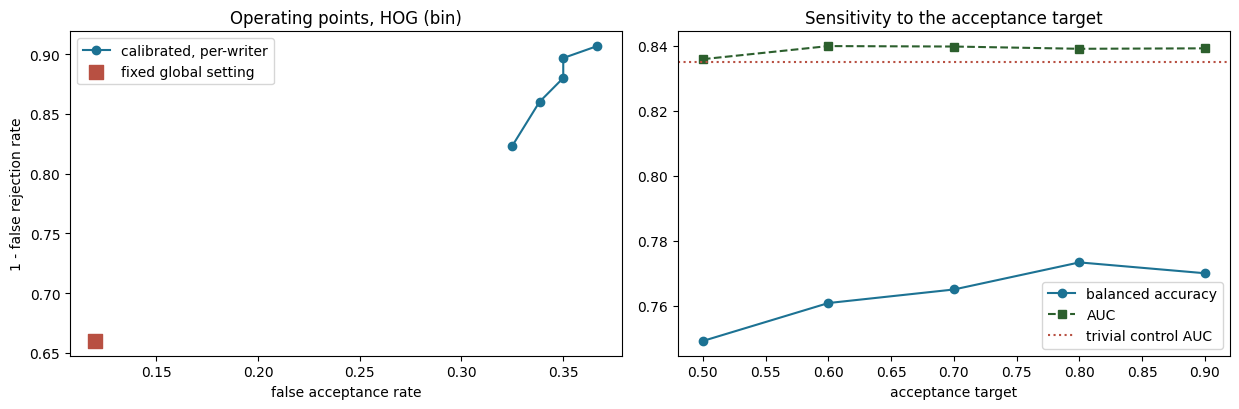

[timer] 6 sweep: 192.1s   (total 2468.7s)


In [15]:
PRIMARY = ("HOG","bin")
SWEEP_TARGETS = (0.50, 0.60, 0.70, 0.80, 0.90)
sweep = []
for t in SWEEP_TARGETS:
    cal = {}
    for wid in DEV:
        s = DS[PRIMARY][wid]; cs, _ = cohort_pool_sigs(PRIMARY[0], PRIMARY[1], wid)
        cal[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, "target", target=t)
    params = {w: {"nu":cal[w]["nu"], "gamma":cal[w]["gamma"]} for w in DEV}
    _, ov = evaluate(PRIMARY, params, f"target={t}")
    sweep.append({"target":t, **{k: ov[k] for k in ("FRR","FAR","AUC","BalAcc","F1")}})
    print(f"  target {t:.2f}  FRR {ov['FRR']:.4f}  FAR {ov['FAR']:.4f}  "
          f"BalAcc {ov['BalAcc']:.4f}  AUC {ov['AUC']:.4f}", flush=True)
SW = pd.DataFrame(sweep); SW.to_csv(OUT_DIR/"operating_point_sweep.csv", index=False)

fx = RES[(RES.Arm==f"{PRIMARY[0]}-{PRIMARY[1]}")&(RES.Selection=="fixed")].iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax[0].plot(SW.FAR, 1-SW.FRR, "o-", color="#1C7293", label="calibrated, per-writer")
ax[0].scatter([fx.FAR], [1-fx.FRR], marker="s", s=90, color="#B85042", zorder=5,
              label="fixed global setting")
ax[0].set_xlabel("false acceptance rate"); ax[0].set_ylabel("1 - false rejection rate")
ax[0].set_title(f"Operating points, {PRIMARY[0]} ({PRIMARY[1]})"); ax[0].legend()
ax[1].plot(SW.target, SW.BalAcc, "o-", color="#1C7293", label="balanced accuracy")
ax[1].plot(SW.target, SW.AUC, "s--", color="#2C5F2D", label="AUC")
ax[1].axhline(ctrl_auc[PRIMARY[1]], ls=":", color="#B85042", label="trivial control AUC")
ax[1].set_xlabel("acceptance target"); ax[1].set_title("Sensitivity to the acceptance target")
ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR/"operating_points.png", dpi=130); plt.show()
mark("6 sweep")

## 8. Decision attribution

The verification decision is a function of the questioned signature and the twelve
enrolled signatures jointly, so attribution is defined over that joint quantity. A
square patch of the questioned signature is occluded, the full feature path is
recomputed on the occluded image, the pair descriptor is rebuilt against every
enrolled signature, and the mean decision function is re-evaluated. The attribution
of a patch is the resulting drop in score, accumulated onto a pixel grid and
averaged where patches overlap.

Recomputing the feature path rather than masking entries of a precomputed feature
vector is necessary: occluding pixels alters the gradient structure of neighbouring
cells, and zeroing elements of an existing HOG vector corresponds to no real image.

Gradient-based attribution is unavailable for this model. A one-class support vector
machine with a radial basis function kernel exposes no differentiable path from
output to input, so Integrated Gradients, DeepLIFT, Grad-CAM and the gradient
variants of SHAP cannot be computed. Occlusion requires only that an input can be
scored.

**Faithfulness, corrected.** A deletion curve records the score as patches are
occluded in order of descending attribution. In v5 each curve was normalised by its
own range, which stretched any ordering producing a smaller total change to span the
full interval and made comparison against random ordering invalid; all three genuine
signatures were consequently reported as worse than random. Every curve for a given
signature is now normalised by one common denominator, the difference between the
unoccluded score and the score of the fully occluded image. A faithful map produces a
curve lying below the random-ordering curve, hence a smaller area.

**Saturation.** Attribution is defined only where the score is locally sensitive to
the input. A signature lying far outside the boundary may be unaffected by occlusion
of any single patch, in which case no map exists. Such cases are recorded as
saturated rather than as maps of uniform zero attribution, and excluded from the
faithfulness summary. This is a property of the decision function, not of the
attribution method, and it bounds where a sensitivity map can be displayed at all.

**Scope.** This component is a score-sensitivity diagnostic. It is not offered as a
forensic explanation and no comparison against examiner-marked regions is attempted;
that standard has been established for gradient-based attribution on this dataset
using expert annotation, and is outside the scope of this experiment.

Attribution: writer 3, HOG (bin), 6 questioned signatures, patch 12, stride 6
  original_3_2.png           genuine score +0.0497  deletion AUC 0.789 vs random 0.219  gain -0.570
  original_3_12.png          genuine score +0.1158  deletion AUC 0.810 vs random 0.222  gain -0.587
  original_3_11.png          genuine score +0.0548  deletion AUC 0.850 vs random 0.202  gain -0.649
  forgeries_3_9.png          forged  score -0.0770  deletion AUC -0.464 vs random -0.060  gain +0.404
  forgeries_3_16.png         forged  score +0.1035  deletion AUC -0.110 vs random 0.221  gain +0.331
  forgeries_3_18.png         forged  score -0.0037  deletion AUC -0.262 vs random 0.151  gain +0.413

ATTRIBUTION FAITHFULNESS (shared denominator per signature)
              file  genuine  base_score  blank_score  denominator  saturated  max_abs_drop  deletion_auc_attr  deletion_auc_random  faithfulness_gain  attr_mass_on_ink  ink_fraction
  original_3_2.png        1      0.0497      -0.7068       0.7565      Fals

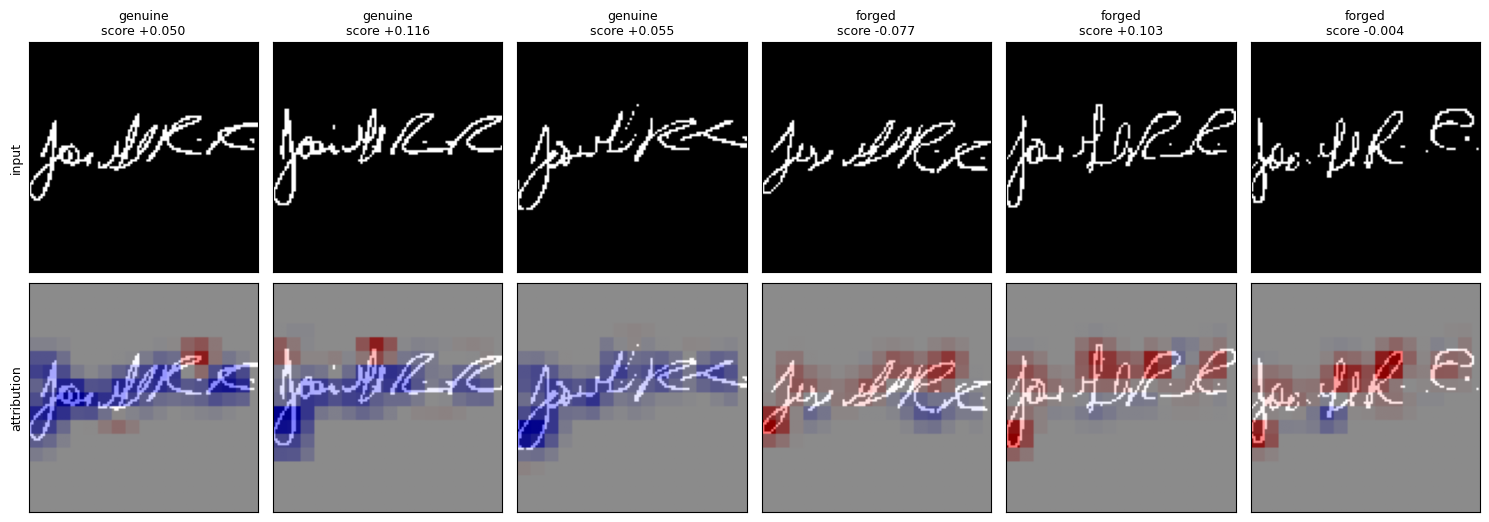

[timer] 7 attribution: 33.8s   (total 2502.5s)


In [16]:
ATTR_ARM = PRIMARY
attr_fn = FEATURE_FNS[ATTR_ARM[0]]; attr_scaler = SC[ATTR_ARM]

def _image(path): return _condition(preprocess_gray(path), ATTR_ARM[1])

def _pair_score(model, pair_sc, img, W):
    v = attr_scaler.transform(attr_fn(img).reshape(1,-1))[0]
    Q = pair_sc.transform(np.array([pair_descriptor(v, t) for t in W]))
    return float(model.decision_function(Q).mean())

def _positions(H, W_, patch, stride):
    return [(t,l) for t in range(0, max(H-patch,0)+1, stride)
                  for l in range(0, max(W_-patch,0)+1, stride)]

def occlusion_map(model, pair_sc, img, W, patch=ATTR_PATCH, stride=ATTR_STRIDE):
    H, W_ = img.shape
    base = _pair_score(model, pair_sc, img, W)
    pos = _positions(H, W_, patch, stride)
    acc = np.zeros((H,W_)); cnt = np.zeros((H,W_)); drops = []
    for (t,l) in pos:
        o = img.copy(); o[t:t+patch, l:l+patch] = 0.0
        d = base - _pair_score(model, pair_sc, o, W)
        drops.append(d); acc[t:t+patch, l:l+patch] += d; cnt[t:t+patch, l:l+patch] += 1
    cnt[cnt==0] = 1
    return acc/cnt, base, pos, np.array(drops)

def deletion_curve(model, pair_sc, img, W, pos, order, base, denom,
                   steps=DELETION_STEPS, patch=ATTR_PATCH):
    """Normalised by a denominator SHARED across orderings for this signature."""
    ks = np.linspace(0, len(order), steps+1)[1:].astype(int)
    o = img.copy(); scores = [base]; prev = 0
    for k in ks:
        for j in order[prev:k]:
            t,l = pos[j]; o[t:t+patch, l:l+patch] = 0.0
        scores.append(_pair_score(model, pair_sc, o, W)); prev = k
    s = np.array(scores)
    return s, float(_trapz((s - (base - denom))/denom, dx=1.0/steps))

cal_attr = CAL[(ATTR_ARM, "margin")]
wid = DEV[0]; s = DS[ATTR_ARM][wid]
m_a, sc_a = fit_pairs(s["D"], cal_attr[wid]["nu"], cal_attr[wid]["gamma"])
Wenr = s["W"]

sel = ([(p,1) for p in writer_splits[wid]["test_genuine"][:ATTR_N_GENUINE]] +
       [(p,0) for p in writer_splits[wid]["test_forged"][:ATTR_N_FORGED]])
print(f"Attribution: writer {wid}, {ATTR_ARM[0]} ({ATTR_ARM[1]}), {len(sel)} questioned "
      f"signatures, patch {ATTR_PATCH}, stride {ATTR_STRIDE}", flush=True)

maps, faith = [], []
for p, lab in sel:
    img = _image(p)
    hm, base, pos, drops = occlusion_map(m_a, sc_a, img, Wenr)
    blank = np.zeros_like(img)
    s_full = _pair_score(m_a, sc_a, blank, Wenr)
    denom = base - s_full
    saturated = (float(np.abs(drops).max()) < SATURATION_TOL) or (abs(denom) < 1e-9)
    if saturated:
        auc_attr = float("nan"); rnd_mean = float("nan"); on_ink = float("nan")
    else:
        _, auc_attr = deletion_curve(m_a, sc_a, img, Wenr, pos, np.argsort(-drops), base, denom)
        rnd = [deletion_curve(m_a, sc_a, img, Wenr, pos,
                              np.random.default_rng(100+r).permutation(len(pos)), base, denom)[1]
               for r in range(DELETION_RANDOM_REPEATS)]
        rnd_mean = float(np.mean(rnd))
        ink = img > INK_THRESH
        on_ink = float(np.abs(hm)[ink].sum()/max(np.abs(hm).sum(), 1e-12))
    maps.append((p.name, lab, img, hm, base, saturated))
    faith.append({"file":p.name, "genuine":lab, "base_score":base, "blank_score":s_full,
                  "denominator":denom, "saturated":saturated,
                  "max_abs_drop":float(np.abs(drops).max()),
                  "deletion_auc_attr":auc_attr, "deletion_auc_random":rnd_mean,
                  "faithfulness_gain": (rnd_mean-auc_attr) if not saturated else float("nan"),
                  "attr_mass_on_ink":on_ink, "ink_fraction":float((img>INK_THRESH).mean())})
    tag = "genuine" if lab else "forged"
    if saturated:
        print(f"  {p.name:26s} {tag:7s} score {base:+.4f}  saturated "
              f"(max |drop| {np.abs(drops).max():.2e}, denom {denom:+.2e})", flush=True)
    else:
        print(f"  {p.name:26s} {tag:7s} score {base:+.4f}  deletion AUC {auc_attr:.3f} "
              f"vs random {rnd_mean:.3f}  gain {rnd_mean-auc_attr:+.3f}", flush=True)

FA = pd.DataFrame(faith); FA.to_csv(OUT_DIR/"attribution_faithfulness.csv", index=False)
print("\n" + "="*112); print("ATTRIBUTION FAITHFULNESS (shared denominator per signature)"); print("="*112)
print(FA.round(4).to_string(index=False))
ok = FA[~FA.saturated]
print(f"\n  informative maps: {len(ok)}/{len(FA)}   saturated: {int(FA.saturated.sum())}")
if len(ok):
    print(f"  mean faithfulness gain over random: {ok.faithfulness_gain.mean():+.4f}  "
          f"({int((ok.faithfulness_gain>0).sum())}/{len(ok)} better than random)")
    print(f"  attribution mass on ink: {ok.attr_mass_on_ink.mean():.1%}  "
          f"(ink occupies {ok.ink_fraction.mean():.1%} of pixels)   "
          f"concentration {ok.attr_mass_on_ink.mean()/max(ok.ink_fraction.mean(),1e-9):.2f}x")
    print(f"\n  v5 for comparison reported a mean gain of -0.0731 under the per-curve")
    print(f"  normalisation; those values were not comparable across orderings.")
else:
    print("  No informative map: every attributed signature sits far enough from the")
    print("  boundary that occluding any single patch leaves the score unchanged.")

fig, axes = plt.subplots(2, len(maps), figsize=(2.5*len(maps), 5.4), squeeze=False)
for j, (name, lab, img, hm, base, sat) in enumerate(maps):
    axes[0][j].imshow(img, cmap="gray")
    axes[0][j].set_title(f"{'genuine' if lab else 'forged'}\nscore {base:+.3f}"
                         + ("\n(saturated)" if sat else ""), fontsize=9)
    v = np.max(np.abs(hm)) or 1.0
    axes[1][j].imshow(img, cmap="gray")
    axes[1][j].imshow(hm, cmap="bwr", vmin=-v, vmax=v, alpha=0.55)
    for a in (axes[0][j], axes[1][j]): a.set_xticks([]); a.set_yticks([])
axes[0][0].set_ylabel("input", fontsize=9); axes[1][0].set_ylabel("attribution", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR/"attribution_maps.png", dpi=130); plt.show()
mark("7 attribution")

## 9. Summary and runtime

In [17]:
print("="*126); print("SUMMARY -- 25 development writers"); print("="*126)
print(RES[SHOW].round(4).to_string(index=False))

print("\n  Trivial control AUC by condition:")
for c in CONDITIONS: print(f"    {c:5s} {ctrl_auc[c]:.4f}")

print("\n  Representations exceeding the trivial control (fixed baseline):")
any_above = False
for c in CONDITIONS:
    for rep in ("RAW","HOG"):
        r = RES[(RES.Rep==rep)&(RES.Condition==c)&(RES.Selection=="fixed")].iloc[0]
        if r.margin_vs_control > 0:
            any_above = True; print(f"    {rep}-{c}: margin {r.margin_vs_control:+.4f}")
if not any_above:
    print("    none -- every representation ranks below nine image statistics under")
    print("    the identical pipeline. The margin, not the absolute AUC, is the result.")

print("\n  Primary arm:", f"{PRIMARY[0]}-{PRIMARY[1]}")
sub = RES[RES.Arm==f"{PRIMARY[0]}-{PRIMARY[1]}"].set_index("Selection")
for selk in ("fixed","target","margin"):
    r = sub.loc[selk]
    print(f"    {selk:7s} FRR {r.FRR:.4f}  FAR {r.FAR:.4f}  BalAcc {r.BalAcc:.4f}  "
          f"AUC {r.AUC:.4f}  FRR@matchedFAR {r.FRR_at_matched_FAR:.4f}")

print(f"\n  Grid self-extension: "
      f"{int(CD.writers_extended.sum())} writer-runs extended, "
      f"{int(CD.still_at_edge.sum())} still at a boundary "
      f"(v5: 21/25 pinned on one arm with no extension)")
if len(FA[~FA.saturated]):
    print(f"  Attribution: {len(FA[~FA.saturated])}/{len(FA)} informative, mean gain "
          f"{FA[~FA.saturated].faithfulness_gain.mean():+.4f}")
print(f"\n  Confirmation writers ({len(CONFIRM)}) remain unevaluated.")

total = time.time()-NB_T0; h, rem = divmod(total, 3600); m_, s_ = divmod(rem, 60)
print("\n" + "="*70); print("RUNTIME"); print("="*70)
print(f"  Google Colaboratory, High-RAM, Python {sys.version.split()[0]}, CPU")
print(f"  OneClassSVM is CPU-only; no GPU or TPU backend exists for this estimator.")
print("-"*70)
for k, v in SECTION_TIMES.items():
    if k == "_last": continue
    print(f"  {k:28s} {v:8.1f}s  ({v/60:5.2f} min)")
print("-"*70)
print(f"  TOTAL {int(h)}h {int(m_)}m {int(s_)}s  ({total/60:.1f} min)")
pd.DataFrame([{"section":k,"seconds":v} for k,v in SECTION_TIMES.items() if k!="_last"]) \
  .to_csv(OUT_DIR/"v6_runtime.csv", index=False)
print(f"\n  Artifacts: {OUT_DIR}")
for fp in sorted(OUT_DIR.glob("*")): print("   ", fp.name)

SUMMARY -- 25 development writers
     Arm Selection    FRR    FAR  Accuracy     F1    AUC  BalAcc  margin_vs_control  AUC_p  FRR_at_matched_FAR
RAW-gray     fixed 0.3767 0.0050    0.8711 0.7503 0.9762  0.8092            -0.0176    NaN              0.4100
RAW-gray    target 0.1933 0.0417    0.9078 0.8612 0.9615  0.8825            -0.0323 0.0343              0.9567
RAW-gray    margin 0.1433 0.0467    0.9211 0.8916 0.9576  0.9050            -0.0362 0.3972              0.2867
HOG-gray     fixed 0.2700 0.1267    0.8256 0.7598 0.8871  0.8017            -0.1067    NaN              0.3067
HOG-gray    target 0.1067 0.2217    0.8167 0.8100 0.8836  0.8358            -0.1102 0.5335              0.3433
HOG-gray    margin 0.1167 0.1967    0.8300 0.8212 0.8708  0.8433            -0.1230 0.1770              0.4567
GEO-gray     fixed 0.3500 0.0000    0.8833 0.7733 0.9938  0.8250             0.0000    NaN              0.3867
GEO-gray    target 0.1833 0.0217    0.9244 0.8776 0.9930  0.8975            -0